# 2 · Sparse index replication with the LASSO
Can SPY be tracked with only a few large-cap stocks? A two-stage approach is used:
1. **Selection:** walk the long-only **LASSO** path and keep the first *n* stocks to enter;
2. **Refit:** re-estimate weights by constrained least squares (long-only, fully invested, minimum tracking error). This removes the L1 shrinkage bias.

Weights are estimated on 2015-2022 and tested **out-of-sample** on 2023 onwards, and compared with plain LASSO weights.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
load = lambda f: pd.read_csv(f"../data/{f}.csv", index_col=0, parse_dates=True)   # refresh: python scripts/fetch_data.py
from finml import tracking

In [2]:
px = load("large_caps")
rets = px.pct_change().dropna()
idx, stocks = rets.pop("SPY"), rets
train, test = slice(None, "2022-12-31"), slice("2023-01-01", None)
rows, books = [], {}
for n in (5, 10, 15, 20, 30):
    w, alpha = tracking.sparse_tracking_portfolio(stocks.loc[train], idx.loc[train], n)
    w_plain, _ = tracking.weights_for_n_names(stocks.loc[train], idx.loc[train], n)
    books[n] = w
    rows.append({"target names": n, "alpha": alpha,
                 **{f"in-sample {k}": v for k, v in tracking.evaluate(w, stocks.loc[train], idx.loc[train]).items() if k in ("names", "tracking error")},
                 **{f"out-of-sample {k}": v for k, v in tracking.evaluate(w, stocks.loc[test], idx.loc[test]).items() if k != "names"},
                 "plain-LASSO out-of-sample TE": tracking.evaluate(w_plain, stocks.loc[test], idx.loc[test])["tracking error"]})
summary = pd.DataFrame(rows).set_index("target names")
ew = stocks.mean(axis=1)
print("Reference - equal-weight basket of all 40 stocks: correlation with SPY "
      f"{np.corrcoef(ew.loc[train], idx.loc[train])[0, 1]:.3f} (2015-22) vs {np.corrcoef(ew.loc[test], idx.loc[test])[0, 1]:.3f} (2023+), "
      f"out-of-sample TE {tracking.tracking_error(ew.loc[test], idx.loc[test]):.2%}")
summary.style.format({"alpha": "{:.1e}", "in-sample tracking error": "{:.2%}", "out-of-sample tracking error": "{:.2%}",
                      "out-of-sample correlation": "{:.3f}", "out-of-sample active return (ann.)": "{:+.2%}", "out-of-sample beta": "{:.2f}",
                      "plain-LASSO out-of-sample TE": "{:.2%}"})

Reference - equal-weight basket of all 40 stocks: correlation with SPY 0.983 (2015-22) vs 0.894 (2023+), out-of-sample TE 6.85%


,alpha,in-sample names,in-sample tracking error,out-of-sample tracking error,out-of-sample correlation,out-of-sample active return (ann.),out-of-sample beta,plain-LASSO out-of-sample TE
target names,,,,,,,,
5,1.2e-04,5,10.27%,11.95%,0.756,-2.28%,0.91,18.51%
10,8.6e-05,10,8.55%,8.48%,0.885,+7.01%,1.07,10.49%
15,5.3e-05,14,5.95%,6.78%,0.905,-0.53%,0.95,7.24%
20,4.0e-05,20,4.88%,6.91%,0.893,-2.74%,0.88,6.12%
30,1.6e-05,30,3.20%,6.50%,0.903,-0.70%,0.78,5.31%


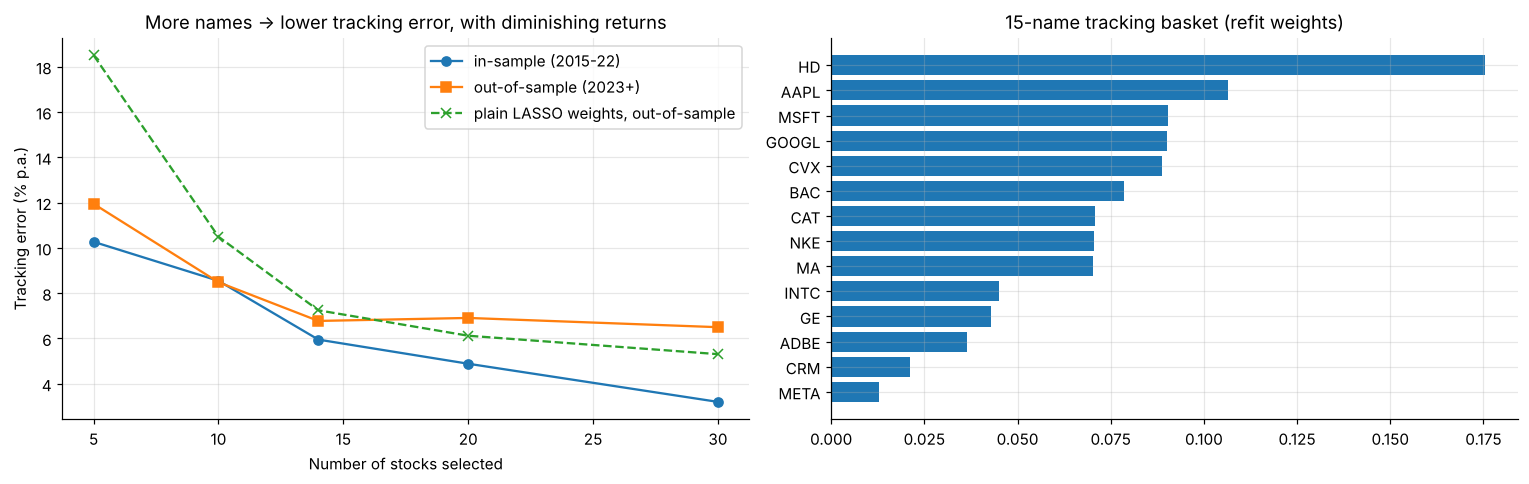

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(summary["in-sample names"], summary["in-sample tracking error"] * 100, "o-", label="in-sample (2015-22)")
ax[0].plot(summary["in-sample names"], summary["out-of-sample tracking error"] * 100, "s-", label="out-of-sample (2023+)")
ax[0].plot(summary["in-sample names"], summary["plain-LASSO out-of-sample TE"] * 100, "x--", label="plain LASSO weights, out-of-sample")
ax[0].set_xlabel("Number of stocks selected"); ax[0].set_ylabel("Tracking error (% p.a.)"); ax[0].legend()
ax[0].set_title("More names → lower tracking error, with diminishing returns")
w = books[15].sort_values(ascending=False); w = w[w > 0]
ax[1].barh(w.index[::-1], w.values[::-1]); ax[1].set_title("15-name tracking basket (refit weights)")
fig.tight_layout(); plt.savefig(IMG / "lasso_tracking.png", bbox_inches="tight"); plt.show()

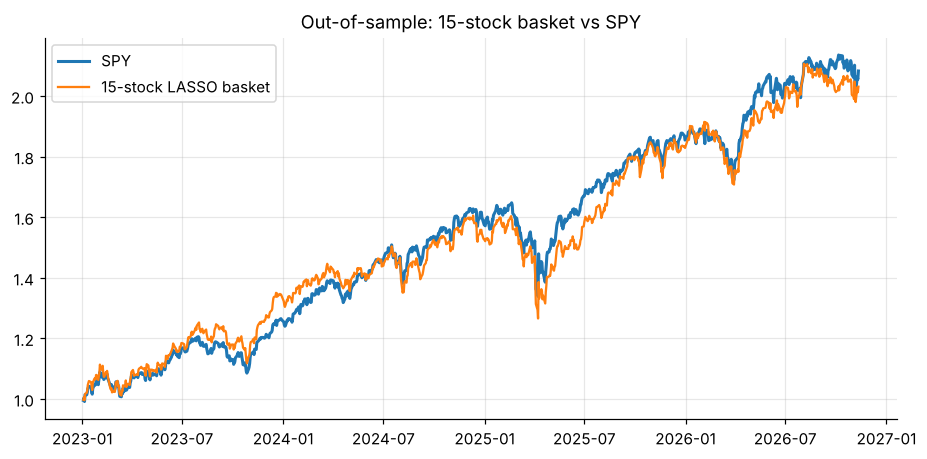

In [4]:
w = books[15]
port = stocks.loc[test, w.index] @ w
plt.plot((1 + idx.loc[test]).cumprod(), label="SPY", lw=2)
plt.plot((1 + port).cumprod(), label="15-stock LASSO basket", lw=1.5)
plt.title("Out-of-sample: 15-stock basket vs SPY"); plt.legend()
plt.savefig(IMG / "lasso_oos.png", bbox_inches="tight"); plt.show()

**Takeaway:** the refit step matters most for small baskets. With 5-15 names, plain LASSO weights are shrunk and then rescaled, which raises tracking error well above the two-stage tracker. Tracking error falls as names are added, with diminishing returns. Out-of-sample error is higher than in-sample because stock dispersion rose sharply after 2023: even an equal-weight basket of all 40 mega-caps dropped from 0.98 to 0.89 correlation with SPY. A sparse tracker has to be re-estimated regularly (e.g. quarterly) to keep up with changing index composition.